# Monte Carlo: 10,000 escenarios con datos reales
## De los precios de SPY a la incertidumbre de tu capital

**Autor:** Dr. Wellcome Peujio Jiotsop Foze &nbsp;·&nbsp; **Institución:** WP Wellness Academy &nbsp;·&nbsp; **Nivel:** Básico — Intermedio  
**Instagram:** [@Peu_well](https://instagram.com/Peu_well)  
**Edición:** YFINANCE · 7 de octubre de 2026 · ejercicio breve para la comunidad

---

### Recursos del Autor

| Recurso | Descripción | Enlace |
|---------|-------------|--------|
| 📗 **eBook WP Quant** | La guía completa de finanzas cuantitativas con Python | [Ver eBook](https://www.wpwellnessacademy.com/wp-quant-la-guia-completa-de-finanzas-cuantitativas-con-python-ebook-digital) |
| 📚 **eBook Finanzas 5.0** | Enfoque moderno basado en datos y Python | [Ver eBook](https://www.wpwellnessacademy.com/finanzas-50-un-enfoque-moderno-basado-en-datos-y-python-ebook-digital) |
| 💻 **Curso Profesional Python para Finanzas 5.0** | De cero a economista cuantitativo | [Ver Curso](https://www.wpwellnessacademy.com/curso-profesional-python-para-finanzas-50) |

**Próximo inicio del curso:** 25 de octubre de 2026.

---

### ¿Qué vas a explorar?

Simularás **USD 10,000** durante **63 jornadas** y medirás las pérdidas de la cola.
63 sesiones equivalen aproximadamente a tres meses: $252/4$.

**Recorrido:** datos → parámetros → escenarios → riesgo → tu experimento.

## 1. Prepara tu entorno

Abre este notebook en **Jupyter o Google Colab** y ejecuta todas las celdas en
orden, con conexión a internet. Los precios se descargan con **`yfinance`**;
no necesitas subir ningún CSV. La primera celda instala `yfinance` y las
dependencias del ejercicio. El encabezado debe mostrar **Edición: YFINANCE**.

> **Objetivo:** cambiar un parámetro, observar el resultado y compartir una conclusión.

In [1]:
%pip install -q --disable-pip-version-check --root-user-action=ignore yfinance==1.7.0 numpy pandas matplotlib scipy

from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from curl_cffi import requests
from IPython.display import display, Markdown
from scipy.stats import norm

AZUL, CIAN, DORADO = "#050f22", "#46dce5", "#eac578"
plt.rcParams.update({
    "figure.figsize": (9, 3.4), "figure.dpi": 130,
    "figure.facecolor": AZUL, "axes.facecolor": AZUL,
    "text.color": "#f7f8fc", "axes.labelcolor": "#f7f8fc",
    "axes.titlecolor": "#f7f8fc", "axes.edgecolor": "#a6b7cc",
    "xtick.color": "#a6b7cc", "ytick.color": "#a6b7cc",
    "font.size": 11, "axes.grid": True, "grid.alpha": .18,
    "legend.facecolor": AZUL, "legend.edgecolor": "#a6b7cc",
})
print(f"EDICIÓN YFINANCE · yfinance {yf.__version__} · entorno listo.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.3/149.3 kB 5.8 MB/s eta 0:00:00
EDICIÓN YFINANCE · yfinance 1.7.0 · entorno listo.


## 2. Los datos reales

Descargamos el **cierre ajustado de SPY** de Yahoo Finance para **2021–2025**.
`auto_adjust=False` conserva la columna **`Adj Close`**; `multi_level_index=False`
entrega columnas simples. `FIN` es exclusivo, por eso usamos **2026-01-01**.
El proveedor puede revisar ajustes históricos: las cifras se recalculan al descargar.

> Los precios son observados. Los escenarios que generaremos son simulados.

In [2]:
TICKER, INICIO, FIN = "SPY", "2021-01-01", "2026-01-01"  # FIN es exclusivo.
sesion = requests.Session(impersonate="chrome", headers={"User-Agent": "Mozilla/5.0"})
datos = yf.download(
    TICKER, start=pd.Timestamp(INICIO, tz="UTC"), end=pd.Timestamp(FIN, tz="UTC"),
    auto_adjust=False, multi_level_index=False, progress=False,
    threads=False, timeout=30, session=sesion,
)
if datos.empty or "Adj Close" not in datos:
    raise RuntimeError("Yahoo no devolvió precios. Espera unos minutos y ejecuta esta celda de nuevo.")
precios = datos["Adj Close"].dropna().astype(float).rename(TICKER)
precios.index = pd.DatetimeIndex(precios.index).tz_localize(None)
assert precios.index.is_unique and precios.index.is_monotonic_increasing
assert np.isfinite(precios).all() and (precios > 0).all() and len(precios) > 1000
assert precios.index.min() < pd.Timestamp("2021-02-01")
assert precios.index.max() >= pd.Timestamp("2025-12-31"), "La descarga está incompleta."
procedencia = {"source": "Yahoo Finance", "client": "yfinance", "version": yf.__version__,
              "ticker": TICKER, "start": INICIO, "end_exclusive": FIN,
              "price_column": "Adj Close", "auto_adjust": False, "timezone_inputs": "UTC",
              "downloaded_at_utc": datetime.now(timezone.utc).isoformat(),
              "first_date": str(precios.index.min().date()),
              "last_date": str(precios.index.max().date()), "price_observations": len(precios)}
print(f"{len(precios):,} cierres ajustados · {precios.index.min():%d/%m/%Y}–{precios.index.max():%d/%m/%Y}")
print(f"Fuente: Yahoo Finance · yfinance {yf.__version__} · columna Adj Close")

1,255 cierres ajustados · 04/01/2021–31/12/2025
Fuente: Yahoo Finance · yfinance 1.7.0 · columna Adj Close


## 3. Del precio a los parámetros

Calculamos el retorno log diario y estimamos drift y volatilidad del GBM:

$$\ell_t=\ln\!\left(\frac{P_t}{P_{t-1}}\right),\qquad
\hat\sigma=s_\ell\sqrt{252},\qquad
\hat\mu=252\bar\ell+\frac{\hat\sigma^2}{2}.$$

$s_\ell$ usa desviación muestral (`ddof=1`). **$\mu$ es drift del modelo**, no CAGR.
El gráfico muestra el historial usado para estimarlo.

,Parámetro,Estimación
0,Volatilidad anual,17.08%
1,Drift anual GBM,15.20%


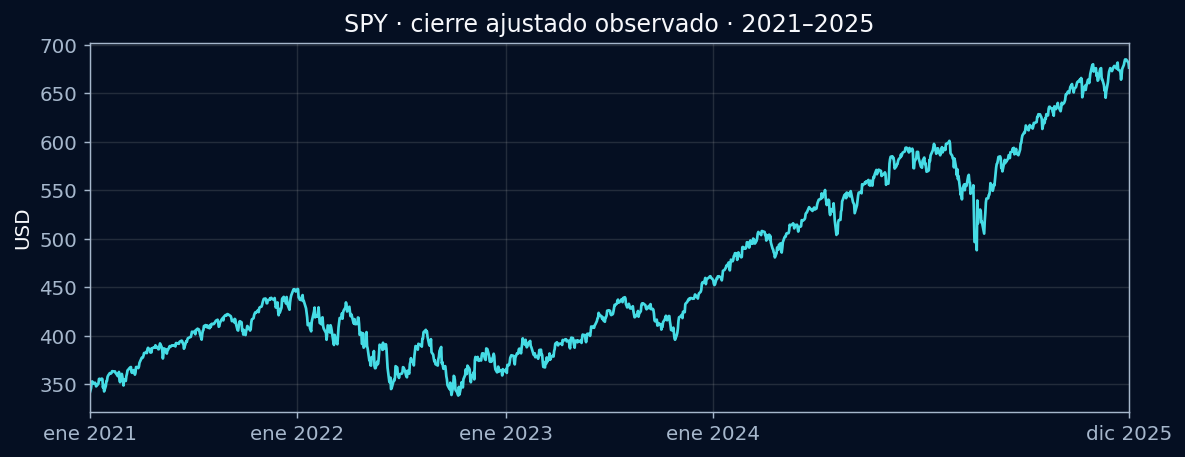

In [3]:
retornos_log = np.log(precios / precios.shift(1)).dropna()
sigma = retornos_log.std(ddof=1) * np.sqrt(252)
mu = 252 * retornos_log.mean() + sigma**2 / 2
display(pd.DataFrame({"Parámetro": ["Volatilidad anual", "Drift anual GBM"],
                      "Estimación": [f"{sigma:.2%}", f"{mu:.2%}"]}))
fig, ax = plt.subplots(layout="constrained")
ax.plot(precios.index, precios, color=CIAN)
ax.set(title="SPY · cierre ajustado observado · 2021–2025", ylabel="USD")
ax.set_xlim(precios.index.min(), precios.index.max())
ax.set_xticks(pd.to_datetime(["2021-01-04", "2022-01-03", "2023-01-03", "2024-01-02", "2025-12-31"]))
ax.set_xticklabels(["ene 2021", "ene 2022", "ene 2023", "ene 2024", "dic 2025"])
plt.show()

## 4. Simula 10,000 escenarios

Cada jornada recibe un shock normal independiente. El paso exacto del GBM es:

$$V_{t+\Delta t}=V_t\exp\!\left[
\left(\mu-\frac{\sigma^2}{2}\right)\Delta t+
\sigma\sqrt{\Delta t}\,Z_t\right],\quad
Z_t\sim N(0,1),\quad \Delta t=\frac{1}{252}.$$

**Modifica `JORNADAS` para probar 21, 63 o 126 sesiones.** La semilla permite
repetir el mismo experimento.

In [4]:
CAPITAL, JORNADAS, ESCENARIOS, SEMILLA = 10_000.0, 63, 10_000, 42
assert CAPITAL > 0 and JORNADAS > 0 and ESCENARIOS >= 1000
rng = np.random.default_rng(SEMILLA)
shocks = rng.normal(size=(JORNADAS, ESCENARIOS))
pasos = (mu - sigma**2 / 2) / 252 + sigma * shocks / np.sqrt(252)
capital_simulado = CAPITAL * np.exp(np.cumsum(pasos, axis=0))
trayectorias = np.vstack([np.full(ESCENARIOS, CAPITAL), capital_simulado])
finales = trayectorias[-1]
print(f"{ESCENARIOS:,} escenarios · {JORNADAS} jornadas · USD {CAPITAL:,.0f} iniciales")

10,000 escenarios · 63 jornadas · USD 10,000 iniciales


### Observa el abanico de resultados

Mostramos 100 caminos para facilitar la lectura; los percentiles usan todos.
La banda **p5–p95 se calcula en cada jornada**: describe escenarios del modelo,
no un intervalo de confianza ni una probabilidad de permanecer dentro de ella.

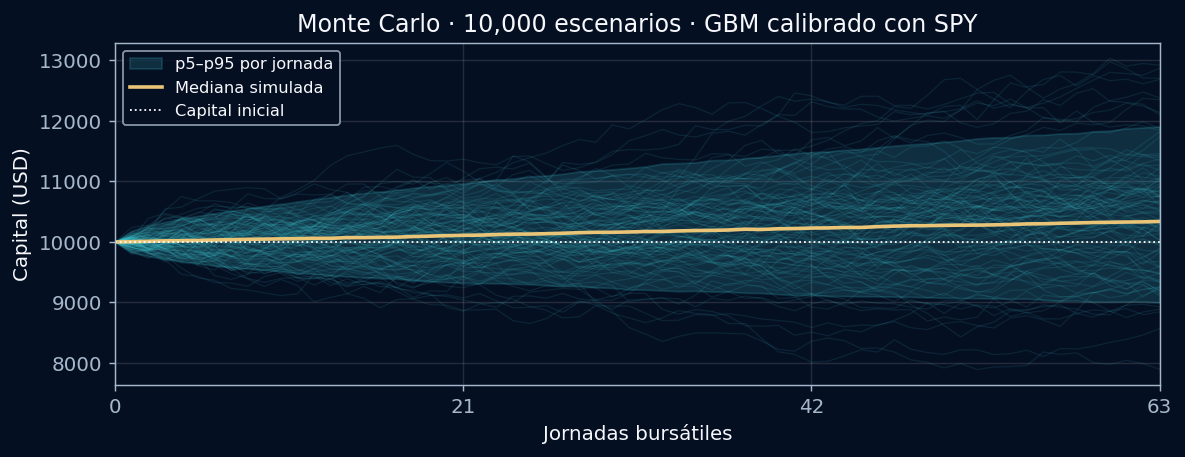

In [5]:
p5, mediana, p95 = np.quantile(trayectorias, [.05, .50, .95], axis=1)
jornadas = np.arange(JORNADAS + 1)
fig, ax = plt.subplots(layout="constrained")
ax.plot(jornadas, trayectorias[:, :100], color=CIAN, alpha=.10, lw=.7)
ax.fill_between(jornadas, p5, p95, color=CIAN, alpha=.16, label="p5–p95 por jornada")
ax.plot(jornadas, mediana, color=DORADO, lw=2, label="Mediana simulada")
ax.axhline(CAPITAL, color="white", ls=":", lw=1, label="Capital inicial")
ax.set(title=f"Monte Carlo · {ESCENARIOS:,} escenarios · GBM calibrado con SPY",
       xlabel="Jornadas bursátiles", ylabel="Capital (USD)", xlim=(0, JORNADAS))
ax.set_xticks([0, JORNADAS // 3, 2 * JORNADAS // 3, JORNADAS])
ax.legend(loc="upper left", fontsize=9)
plt.show()

## 5. ¿Qué ocurre en el peor 5%?

Definimos **pérdida en USD**; una pérdida negativa es una ganancia:

$$L=V_0-V_T,\qquad \mathrm{VaR}_{95\%}=Q_{0.95}(L),\qquad
\mathrm{CVaR}_{95\%}=E[L\mid L\geq\mathrm{VaR}_{95\%}].$$

VaR marca el umbral. CVaR promedia las pérdidas de la cola. Ambos dependen del
horizonte y de los supuestos del modelo.

,Resultado,Valor
0,Capital final mediano,"USD 10,339.13"
1,VaR 95%,"USD 1,001.46"
2,CVaR 95%,"USD 1,321.95"
3,Escenarios con pérdida,34.99%


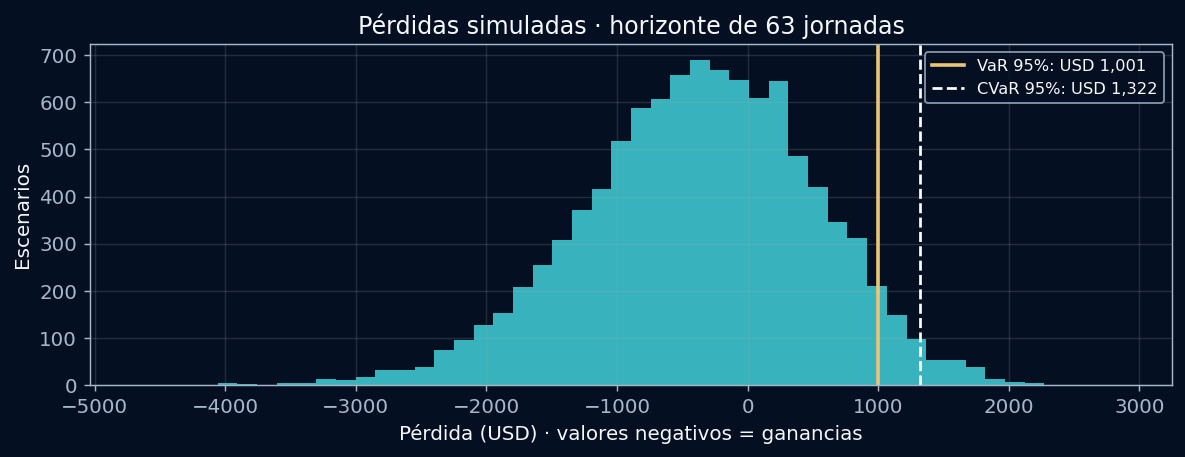

In [6]:
perdidas = CAPITAL - finales
var95 = np.quantile(perdidas, .95)
cvar95 = perdidas[perdidas >= var95].mean()
prob_perder = (finales < CAPITAL).mean()
display(pd.DataFrame({"Resultado": ["Capital final mediano", "VaR 95%", "CVaR 95%", "Escenarios con pérdida"],
    "Valor": [f"USD {np.median(finales):,.2f}", f"USD {var95:,.2f}",
              f"USD {cvar95:,.2f}", f"{prob_perder:.2%}"]}))
fig, ax = plt.subplots(layout="constrained")
ax.hist(perdidas, bins=50, color=CIAN, alpha=.80)
ax.axvline(var95, color=DORADO, lw=2, label=f"VaR 95%: USD {var95:,.0f}")
ax.axvline(cvar95, color="white", ls="--", label=f"CVaR 95%: USD {cvar95:,.0f}")
ax.set(title=f"Pérdidas simuladas · horizonte de {JORNADAS} jornadas",
       xlabel="Pérdida (USD) · valores negativos = ganancias", ylabel="Escenarios")
ax.legend(fontsize=9)
plt.show()

## 6. Comprueba y participa

Contrastamos la media simulada con $E[V_T]=V_0e^{\mu T}$ y la proporción de
pérdida con la solución normal del GBM. La tolerancia usa el error de Monte Carlo.
Luego repetimos con **drift cero y los mismos shocks**.

In [7]:
T = JORNADAS / 252
media_teorica = CAPITAL * np.exp(mu * T)
prob_teorica = norm.cdf(-(mu - sigma**2 / 2) * np.sqrt(T) / sigma)
error_media = media_teorica * np.sqrt(np.expm1(sigma**2 * T) / ESCENARIOS)
error_prob = np.sqrt(prob_teorica * (1 - prob_teorica) / ESCENARIOS)
assert trayectorias.shape == (JORNADAS + 1, ESCENARIOS)
assert np.isfinite(trayectorias).all() and (trayectorias > 0).all()
assert abs(finales.mean() - media_teorica) < 5 * error_media
assert abs(prob_perder - prob_teorica) < 5 * error_prob
assert cvar95 >= var95
finales_sin_drift = CAPITAL * np.exp(-sigma**2 * T / 2 + sigma * shocks.sum(axis=0) / np.sqrt(252))
display(pd.DataFrame({"Supuesto de drift": ["Estimado con SPY", "Cero"],
    "Escenarios con pérdida": [f"{prob_perder:.2%}", f"{(finales_sin_drift < CAPITAL).mean():.2%}"]}))
print("✓ Datos, dimensiones, positividad, VaR/CVaR y contraste analítico verificados.")

,Supuesto de drift,Escenarios con pérdida
0,Estimado con SPY,34.99%
1,Cero,52.20%


✓ Datos, dimensiones, positividad, VaR/CVaR y contraste analítico verificados.


### Tu turno · comenta MONTECARLO

1. Prueba **21 y 126 jornadas**. ¿Cómo cambian VaR y CVaR?
2. ¿Por qué cambia la proporción de pérdidas al poner el drift en cero?
3. Comparte tu horizonte, VaR y una frase sobre el resultado.

**Alcance:** parámetros estimados con 2021–2025, volatilidad constante y shocks
normales. No se incluyen comisiones, impuestos ni conversión a MXN. Las probabilidades
son del modelo; este ejercicio no valida pronósticos fuera de muestra.

### Fuentes

- [Yahoo Finance · historial de SPY](https://finance.yahoo.com/quote/SPY/history/).
- [yfinance · documentación oficial de descarga](https://ranaroussi.github.io/yfinance/reference/api/yfinance.download.html).
- [MIT OCW · notas de movimiento browniano geométrico](https://ocw.mit.edu/courses/18-s096-topics-in-mathematics-with-applications-in-finance-fall-2013/32f868169964ba3cf5015de880cf2172_MIT18_S096F13_lecnote9.pdf).

---

**WP Wellness Academy** · [wpwellnessacademy.com](https://www.wpwellnessacademy.com)